First five rows:
   Unnamed: 0                            key  fare_amount  \
0    24238194    2015-05-07 19:52:06.0000003          7.5   
1    27835199    2009-07-17 20:04:56.0000002          7.7   
2    44984355   2009-08-24 21:45:00.00000061         12.9   
3    25894730    2009-06-26 08:22:21.0000001          5.3   
4    17610152  2014-08-28 17:47:00.000000188         16.0   

           pickup_datetime  pickup_longitude  pickup_latitude  \
0  2015-05-07 19:52:06 UTC        -73.999817        40.738354   
1  2009-07-17 20:04:56 UTC        -73.994355        40.728225   
2  2009-08-24 21:45:00 UTC        -74.005043        40.740770   
3  2009-06-26 08:22:21 UTC        -73.976124        40.790844   
4  2014-08-28 17:47:00 UTC        -73.925023        40.744085   

   dropoff_longitude  dropoff_latitude  passenger_count  
0         -73.999512         40.723217                1  
1         -73.994710         40.750325                1  
2         -73.962565         40.772647             

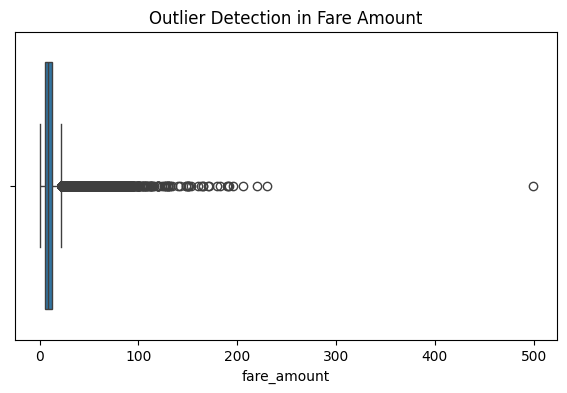

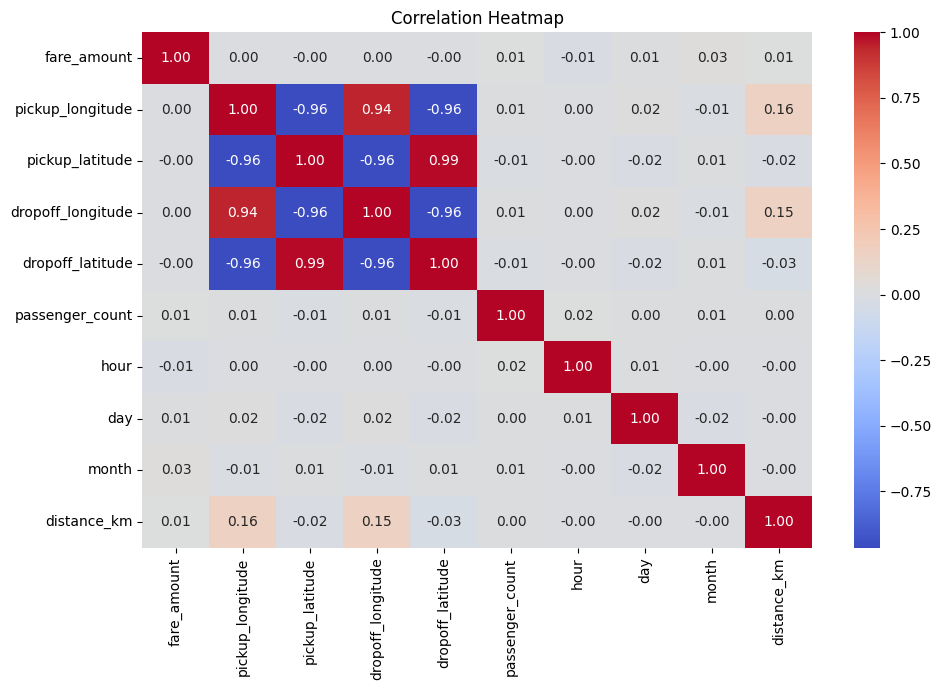


Correlation with fare_amount:
fare_amount          1.000000
month                0.026633
passenger_count      0.013065
distance_km          0.012512
day                  0.006555
dropoff_longitude    0.001479
pickup_longitude     0.000512
pickup_latitude     -0.001956
dropoff_latitude    -0.002266
hour                -0.013132
Name: fare_amount, dtype: float64

Training samples: 141377
Testing samples: 35345

 Linear Regression
R2 Score: 0.0016
RMSE: 4.1372
MAE: 3.2834

 Random Forest Regression
R2 Score: 0.7375
RMSE: 2.1212
MAE: 1.4992

Model Comparison:
            Model  R2 Score     RMSE      MAE
Linear Regression  0.001613 4.137214 3.283419
    Random Forest  0.737542 2.121235 1.499167


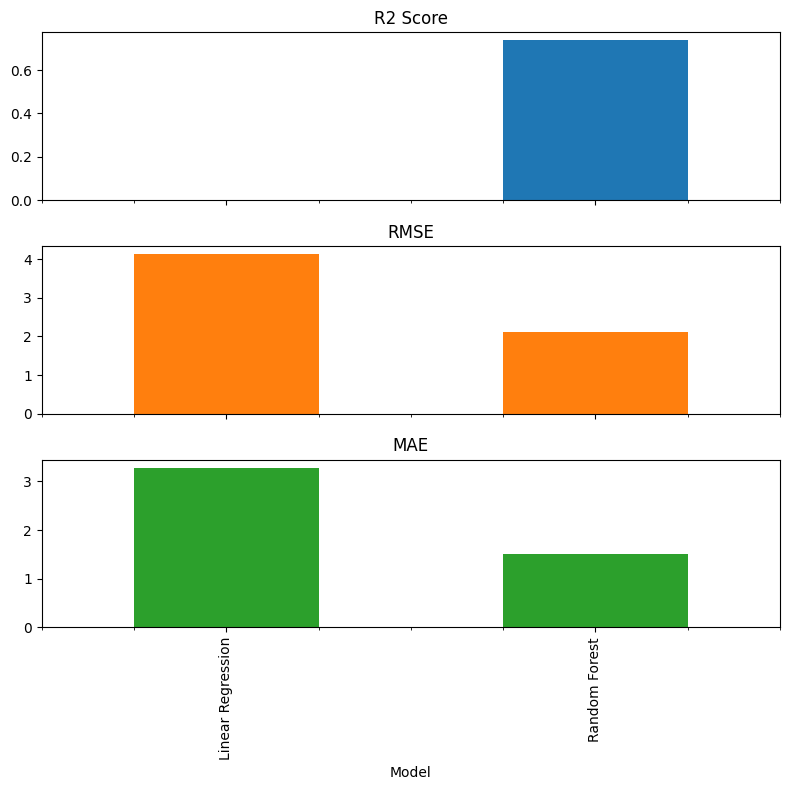


Sample ride features:
       pickup_longitude  pickup_latitude  dropoff_longitude  dropoff_latitude  \
84189        -74.003247        40.732648         -73.915055         40.706077   

       passenger_count  hour  day  month  distance_km  
84189                1     4    8      4     0.092108  
Actual fare: 17.7
Linear Regression prediction: 8.92
Random Forest prediction: 17.75


In [3]:
#final
# Uber Fare Prediction using Linear Regression and Random Forest

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

# 1. Load dataset
df = pd.read_csv("uber.csv")

print("First five rows:")
print(df.head())

print("\nDataset information:")
print(df.info())

print("\nMissing values:")
print(df.isnull().sum())

# 2. Pre-process dataset

# Remove unnecessary columns
df.drop(columns=["Unnamed: 0", "key"], errors="ignore", inplace=True)

# Convert pickup_datetime into datetime format
df["pickup_datetime"] = pd.to_datetime(
    df["pickup_datetime"], errors="coerce", utc=True
)

# Remove missing values
df.dropna(inplace=True)

# Remove invalid fare, coordinates and passenger counts
df = df[
    (df["fare_amount"] > 0) &
    (df["pickup_longitude"].between(-180, 180)) &
    (df["dropoff_longitude"].between(-180, 180)) &
    (df["pickup_latitude"].between(-90, 90)) &
    (df["dropoff_latitude"].between(-90, 90)) &
    (df["pickup_longitude"] != 0) &
    (df["dropoff_longitude"] != 0) &
    (df["pickup_latitude"] != 0) &
    (df["dropoff_latitude"] != 0) &
    (df["passenger_count"].between(1, 6))
].copy()

# Extract hour, day and month
df["hour"] = df["pickup_datetime"].dt.hour
df["day"] = df["pickup_datetime"].dt.day
df["month"] = df["pickup_datetime"].dt.month

# Calculate distance using Euclidean formula
df["distance_km"] = np.sqrt(
    (df["dropoff_longitude"] - df["pickup_longitude"]) ** 2
    + (df["dropoff_latitude"] - df["pickup_latitude"]) ** 2
)

# Remove zero-distance and implausibly long trips
df = df[
    (df["distance_km"] > 0) &
    (df["distance_km"] <= 100)
].copy()

# Remove original datetime column because features are extracted
df.drop(columns=["pickup_datetime"], inplace=True)

print("\nDataset after preprocessing:")
print(df.head())
print("Shape:", df.shape)

# 3. Identify outliers using IQR
Q1 = df["fare_amount"].quantile(0.25)
Q3 = df["fare_amount"].quantile(0.75)
IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

outliers = df[
    (df["fare_amount"] < lower) |
    (df["fare_amount"] > upper)
]

print("\nLower limit:", lower)
print("Upper limit:", upper)
print("Number of fare outliers:", len(outliers))

# Visualize outliers
plt.figure(figsize=(7, 4))
sns.boxplot(x=df["fare_amount"])
plt.title("Outlier Detection in Fare Amount")
plt.show()

# Remove extreme fare outliers
df = df[
    df["fare_amount"].between(lower, upper)
].copy()

# 4. Check correlation
correlation = df.corr(numeric_only=True)

plt.figure(figsize=(10, 7))
sns.heatmap(correlation, annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()

print("\nCorrelation with fare_amount:")
print(correlation["fare_amount"].sort_values(ascending=False))

# 5. Select features and target
X = df.drop(columns=["fare_amount"])
y = df["fare_amount"]

# Split into training and testing data
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("\nTraining samples:", len(X_train))
print("Testing samples:", len(X_test))

# 6. Linear Regression
lr = LinearRegression()
lr.fit(X_train, y_train)

y_pred_lr = lr.predict(X_test)

# 7. Random Forest Regression
rf = RandomForestRegressor(
    n_estimators=50,
    random_state=42,
    n_jobs=-1
)
rf.fit(X_train, y_train)

y_pred_rf = rf.predict(X_test)

# 8. Evaluate both models
def evaluate_model(name, actual, predicted):
    r2 = r2_score(actual, predicted)
    rmse = np.sqrt(mean_squared_error(actual, predicted))
    mae = mean_absolute_error(actual, predicted)

    print("\n", name)
    print("R2 Score:", round(r2, 4))
    print("RMSE:", round(rmse, 4))
    print("MAE:", round(mae, 4))

    return [r2, rmse, mae]

lr_scores = evaluate_model(
    "Linear Regression", y_test, y_pred_lr
)

rf_scores = evaluate_model(
    "Random Forest Regression", y_test, y_pred_rf
)

# 9. Compare model scores
results = pd.DataFrame({
    "Model": ["Linear Regression", "Random Forest"],
    "R2 Score": [lr_scores[0], rf_scores[0]],
    "RMSE": [lr_scores[1], rf_scores[1]],
    "MAE": [lr_scores[2], rf_scores[2]]
})

print("\nModel Comparison:")
print(results.to_string(index=False))

# 10. Plot comparison
results.set_index("Model")[["R2 Score", "RMSE", "MAE"]].plot(
    kind="bar", subplots=True, figsize=(8, 8), legend=False
)
plt.tight_layout()
plt.show()

# 11. Predict a sample ride from the test set
sample = X_test.iloc[[0]]

print("\nSample ride features:")
print(sample)

print("Actual fare:", round(y_test.iloc[0], 2))
print("Linear Regression prediction:", round(lr.predict(sample)[0], 2))
print("Random Forest prediction:", round(rf.predict(sample)[0], 2))
